# INFO 4360 Project – Phase 2: Exploration, Text Mining Basics, and Phase 3 Plan
**Student:** Liz | **Data:** UCI Drug Reviews (Drugs.com)

**Where the project stands after Phase 1 feedback.** The proposal predicted whether a review is
dissatisfied (rating ≤ 4). Feedback raised three questions (answered in the Phase 3 plan at the end):
1. Why predict satisfaction when the rating is already there?
2. How do we separate how patients describe *their condition* from how they describe *the drug*?
3. TF-IDF top words differ by drug/condition: how do we handle that?

This notebook explores the data with those three questions in mind. `usefulCount` is only known
after a review is posted, so it is **not** used as a control or feature anywhere.

**To run:** put the two UCI `.csv` files in the repo's `data/` folder, then Run All. This notebook is
self-contained (all helper functions are defined in section 0), so it needs no other repo files.

## 0. Setup and helper functions
Reusable functions are defined once here and called throughout. If your team prefers, move them into
`src/` later and import them.

In [1]:
import html
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

### 0a. Loading, cleaning, features

In [2]:
DATA_DIR = next((p for p in [Path("data"), Path("../data")] if p.exists()), Path("data"))
RESULTS_DIR = DATA_DIR.parent / "results"
TRAIN_FILE = "drugsComTrain_raw.tsv"
TEST_FILE = "drugsComTest_raw.tsv"

DISSATISFIED_CUTOFF = 4          # rating <= 4 -> dissatisfied
POST_HOC_COLS = ["usefulCount"]  # only known AFTER posting: never used as a control/feature


def load_reviews(data_dir=DATA_DIR, train_file=TRAIN_FILE, test_file=TEST_FILE):
    """Read the provided train/test TSVs and stack them with a `split` column."""
    frames = []
    for name, split in [(train_file, "train"), (test_file, "test")]:
        path = Path(data_dir) / name
        df = pd.read_csv(path, sep="\t")
        if "Unnamed: 0" in df.columns:
            df = df.rename(columns={"Unnamed: 0": "uniqueID"})
        df["split"] = split
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def clean_review(text):
    """Unescape HTML entities (e.g. &#039;), drop wrapping quotes, collapse whitespace."""
    if not isinstance(text, str):
        return ""
    text = html.unescape(text).strip().strip('"')
    return re.sub(r"\s+", " ", text)


def clean_condition(cond):
    """Some `condition` values are scraping artifacts (e.g. '3</span> users found this
    comment helpful.'). Set those to NaN instead of treating them as real conditions."""
    if not isinstance(cond, str) or "</span>" in cond or "users found" in cond:
        return np.nan
    return cond.strip()


def add_basic_features(df):
    """Add cleaned text, target, date parts, and simple style features.
    Style features use the ORIGINAL casing, so they are computed before lowercasing."""
    df = df.copy()
    df["review_clean"] = df["review"].map(clean_review)
    df["condition_clean"] = df["condition"].map(clean_condition)
    df["date"] = pd.to_datetime(df["date"], format="%B %d, %Y", errors="coerce")
    df["year"] = df["date"].dt.year
    df["dissatisfied"] = (df["rating"] <= DISSATISFIED_CUTOFF).astype(int)

    txt = df["review_clean"]
    df["n_chars"] = txt.str.len()
    df["n_words"] = txt.str.split().str.len()
    df["n_sentences"] = txt.map(lambda t: max(1, len(re.findall(r"[.!?]+", t))))
    df["exclam_count"] = txt.str.count("!")
    df["question_count"] = txt.str.count(r"\?")
    letters = txt.str.count(r"[A-Za-z]").replace(0, np.nan)
    df["caps_ratio"] = (txt.str.count(r"[A-Z]") / letters).fillna(0)
    return df


def _name_tokens(*names, min_len=4):
    toks = set()
    for n in names:
        if isinstance(n, str):
            toks |= {t.lower() for t in re.split(r"[^A-Za-z0-9]+", n) if len(t) >= min_len}
    return toks


def _sub_tokens(text, toks, placeholder):
    if not toks:
        return text
    pat = re.compile(r"\b(" + "|".join(map(re.escape, sorted(toks))) + r")\w*\b", re.I)
    return text.map(lambda t: pat.sub(placeholder, t))


def mask_drug_and_condition(df, text_col="review_clean", out_col="review_masked"):
    """Replace each review's OWN drug-name and condition words with placeholders so a
    text model cannot just learn 'which drug/condition is this'. Other drugs mentioned
    (e.g. 'switched from Zoloft') are kept on purpose: they carry switching information.
    Regexes are compiled once per (drugName, condition) pair, not once per row."""
    df = df.copy()
    df[out_col] = df[text_col]
    keys = df[["drugName", "condition_clean"]].fillna("")
    for _, idx in keys.groupby(["drugName", "condition_clean"]).groups.items():
        row = df.loc[idx[0]]
        text = df.loc[idx, text_col]
        text = _sub_tokens(text, _name_tokens(row["drugName"]), " drugx ")
        text = _sub_tokens(text, _name_tokens(row["condition_clean"]), " condx ")
        df.loc[idx, out_col] = text
    return df


def top_conditions(df, n=10, min_drugs=3):
    """Conditions with the most reviews that also have >= `min_drugs` distinct drugs,
    so that within-condition drug comparisons are possible."""
    g = df.groupby("condition_clean").agg(n_reviews=("rating", "size"), n_drugs=("drugName", "nunique"))
    return g[g.n_drugs >= min_drugs].sort_values("n_reviews", ascending=False).head(n)

### 0b. Text mining helpers

In [3]:
DOMAIN_STOPWORDS = {
    "drug", "drugx", "condx", "medication", "medicine", "pill", "pills", "mg", "just", "like",
    "im", "ive", "ve", "don", "didn", "doesn", "wasn", "got", "get", "going", "took", "taking",
    "take", "taken", "day", "days", "ve", "ll", "really", "quot", "039",
}
STOPWORDS = sorted(set(ENGLISH_STOP_WORDS) | DOMAIN_STOPWORDS)


# ---------- frequency ----------
def top_terms(texts, n=20, ngram_range=(1, 1), min_df=5):
    """Most frequent terms (document frequency) after stop-word removal."""
    cv = CountVectorizer(stop_words=STOPWORDS, ngram_range=ngram_range, min_df=min_df)
    X = cv.fit_transform(texts)
    freq = np.asarray((X > 0).sum(axis=0)).ravel()
    s = pd.Series(freq, index=cv.get_feature_names_out()).sort_values(ascending=False)
    return (s / X.shape[0]).head(n)  # share of reviews containing the term


def tfidf_top_terms_by_group(df, group_col, groups, text_col="review_masked", n=15, min_df=5):
    """Top mean-TF-IDF terms fitted separately inside each group (e.g. each condition)."""
    out = {}
    for g in groups:
        texts = df.loc[df[group_col] == g, text_col]
        tv = TfidfVectorizer(stop_words=STOPWORDS, min_df=min(min_df, max(1, len(texts) // 20)))
        X = tv.fit_transform(texts)
        m = np.asarray(X.mean(axis=0)).ravel()
        terms = tv.get_feature_names_out()
        out[g] = list(terms[np.argsort(m)[::-1][:n]])
    return out


def jaccard_matrix(term_lists):
    """Pairwise Jaccard overlap between the top-term sets of each group."""
    keys = list(term_lists)
    M = pd.DataFrame(index=keys, columns=keys, dtype=float)
    for a in keys:
        for b in keys:
            A, B = set(term_lists[a]), set(term_lists[b])
            M.loc[a, b] = len(A & B) / max(1, len(A | B))
    return M


def weighted_log_odds(texts_a, texts_b, prior_texts, alpha0=500.0, min_count=10):
    """Monroe et al. (2008) log-odds ratio with an informative Dirichlet prior (z-scored).
    Positive z = term is distinctive of group A; negative = group B. Using the whole
    condition as the prior keeps rare words from dominating."""
    cv = CountVectorizer(stop_words=STOPWORDS, min_df=3)
    cv.fit(prior_texts)
    ya = np.asarray(cv.transform(texts_a).sum(axis=0)).ravel().astype(float)
    yb = np.asarray(cv.transform(texts_b).sum(axis=0)).ravel().astype(float)
    yp = np.asarray(cv.transform(prior_texts).sum(axis=0)).ravel().astype(float)
    alpha = alpha0 * yp / yp.sum()
    na, nb = ya.sum(), yb.sum()
    la = np.log((ya + alpha) / (na + alpha0 - ya - alpha))
    lb = np.log((yb + alpha) / (nb + alpha0 - yb - alpha))
    z = (la - lb) / np.sqrt(1.0 / (ya + alpha) + 1.0 / (yb + alpha))
    res = pd.DataFrame({"term": cv.get_feature_names_out(), "z": z, "count_a": ya, "count_b": yb})
    return res[(res.count_a + res.count_b) >= min_count].sort_values("z", ascending=False)


def within_condition_distinctive(df, conditions, text_col="review_masked", n=10):
    """For each condition: terms most tied to dissatisfied (z>0) vs satisfied (z<0) reviews."""
    rows = []
    for c in conditions:
        sub = df[df["condition_clean"] == c]
        a = sub.loc[sub.dissatisfied == 1, text_col]
        b = sub.loc[sub.dissatisfied == 0, text_col]
        if len(a) < 30 or len(b) < 30:
            continue
        res = weighted_log_odds(a, b, sub[text_col])
        rows.append({"condition": c,
                     "dissatisfied_terms": ", ".join(res.head(n).term),
                     "satisfied_terms": ", ".join(res.tail(n).term[::-1])})
    return pd.DataFrame(rows)


# ---------- sentiment ----------
def vader_compound(texts):
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    return pd.Series([sia.polarity_scores(t)["compound"] for t in texts], index=getattr(texts, "index", None))


# ---------- lexicon features (cheap first pass at 'condition vs drug experience') ----------
CONDITION_CUES = r"\b(i have|i had|i was diagnosed|diagnosed|suffer\w*|my symptoms?|history of|for years|since i was|my doctor|my (anxiety|depression|pain|acne|periods?))\b"
DRUG_CUES = r"\b(side effects?|helped|worked|work(s|ing)?|started|stopped|switched|dose|dosage|weeks?|months?|nausea|headaches?|weight gain|gained|insomnia|dizz\w+|rash|refill|expensive|cost|insurance)\b"
DOSE_RE = r"\b\d+(\.\d+)?\s?(mg|mcg|ml|g)\b"
DURATION_RE = r"\b\d+\s?(day|days|week|weeks|month|months|year|years)\b"
SIDE_EFFECT_RE = r"\b(side effects?|nausea|headaches?|dizz\w+|weight gain|gained|insomnia|rash|vomit\w*|drows\w+|fatigue|tired|dry mouth|sweat\w*|anxious|mood swings?|bleeding|spotting|cramps?|libido|constipat\w+|diarrhea)\b"
INEFFECTIVE_RE = r"\b(did not work|didn'?t work|doesn'?t work|no effect|no difference|not working|stopped working|useless|waste)\b"
COST_RE = r"\b(expensive|cost|costs|insurance|copay|price|afford\w*)\b"
STOP_RE = r"\b(stopped|quit|discontinued|switched|came off|went off|taken off|got off)\b"


def _nc(pat):
    """Turn capturing groups into non-capturing ones (avoids pandas regex-group warnings)."""
    return re.sub(r"\((?!\?)", "(?:", pat)


def lexicon_features(texts):
    """Counts of cue words/phrases. Transparent baseline that Claude's extraction will be compared against."""
    t = texts.str.lower()
    return pd.DataFrame({
        "n_side_effect_terms": t.str.count(_nc(SIDE_EFFECT_RE)),
        "mentions_dose": t.str.contains(_nc(DOSE_RE)).astype(int),
        "mentions_duration": t.str.contains(_nc(DURATION_RE)).astype(int),
        "says_ineffective": t.str.contains(_nc(INEFFECTIVE_RE)).astype(int),
        "mentions_cost": t.str.contains(_nc(COST_RE)).astype(int),
        "stopped_or_switched": t.str.contains(_nc(STOP_RE)).astype(int),
    }, index=texts.index)


def tag_sentences(text):
    """Heuristic sentence tags: 'condition' (about the patient's own condition/history),
    'drug' (about the drug experience), 'mixed' (both kinds of cue), or 'other'."""
    sents = [s for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
    tags = []
    for s in sents:
        low = s.lower()
        c, d = bool(re.search(CONDITION_CUES, low)), bool(re.search(DRUG_CUES, low))
        tags.append("mixed" if (c and d) else "drug" if d else "condition" if c else "other")
    return tags


def sentence_tag_shares(texts):
    shares = []
    for t in texts:
        tags = tag_sentences(t)
        n = max(1, len(tags))
        shares.append({k: tags.count(k) / n for k in ["condition", "drug", "mixed", "other"]})
    return pd.DataFrame(shares, index=texts.index)

### 0c. Claude extraction helpers (used in section 3)

In [4]:
MODEL = "claude-haiku-5-5"   # small/cheap model is enough for extraction; swap if the class key limits models

SYSTEM_PROMPT = """You analyze patient drug reviews. Separate what the patient says about their OWN CONDITION
{
  "condition_description": {"mentioned": true|false, "summary": "<=15 words or null"},
  "drug_experience": {
    "effectiveness": "worked" | "partial" | "did_not_work" | "not_stated",
    "side_effects": ["short phrase", ...],
    "dosage_or_duration": "short phrase or null",
    "cost_or_access_issue": true|false,
    "stopped_or_switched": true|false
  },
  "main_reason_for_dissatisfaction": "side_effects" | "ineffective" | "cost_access" | "condition_worsened" | "other" | "none_expressed"
}
Use only what the review states. Do not infer a rating."""


def build_user_message(review, drug, condition):
    return f"Drug: {drug}\nCondition: {condition}\nReview: {review}"


def extract_reasons(review, drug, condition, client, model=MODEL):
    """One review -> parsed dict (or {'error': ...} if the reply is not valid JSON)."""
    msg = client.messages.create(
        model=model, max_tokens=400, system=SYSTEM_PROMPT,
        messages=[{"role": "user", "content": build_user_message(review, drug, condition)}],
    )
    text = "".join(b.text for b in msg.content if getattr(b, "type", "") == "text").strip()
    text = text.removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        return {"error": "invalid_json", "raw": text[:300]}


def run_sample(df, n=20, out_path=None, seed=42):
    """Stratified sample (half dissatisfied, half not) -> JSONL. Run by hand, review the output."""
    import anthropic
    out_path = out_path or RESULTS_DIR / "claude_sample.jsonl"
    client = anthropic.Anthropic()  # reads ANTHROPIC_API_KEY
    half = n // 2
    sample = pd.concat([df[df.dissatisfied == 1].sample(half, random_state=seed),
                        df[df.dissatisfied == 0].sample(half, random_state=seed)])
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "w") as f:
        for _, r in sample.iterrows():
            res = extract_reasons(r.review_clean, r.drugName, r.condition_clean, client)
            f.write(json.dumps({"uniqueID": int(r.uniqueID), "rating": int(r.rating), "result": res}) + "\n")
    return out_path

## 1. Data Exploration

In [5]:

from pathlib import Path

# Look for the project's data folder
DATA_DIR = next(
    (p for p in [Path("data"), Path("../data")] if p.is_dir()),
    Path("data")
)

RESULTS_DIR = DATA_DIR.parent / "results"

DISSATISFIED_CUTOFF = 4
POST_HOC_COLS = ["usefulCount"]


def load_reviews(data_dir=DATA_DIR):
    """Load train and test drug reviews from CSV or TSV files."""

    data_dir = Path(data_dir)

    # Support either CSV or TSV filenames
    train_options = [
        "drugsComTrain_raw.csv",
        "drugsComTrain_raw.tsv"
    ]
    test_options = [
        "drugsComTest_raw.csv",
        "drugsComTest_raw.tsv"
    ]

    train_path = next(
        (data_dir / name for name in train_options
         if (data_dir / name).is_file()),
        None
    )
    test_path = next(
        (data_dir / name for name in test_options
         if (data_dir / name).is_file()),
        None
    )

    if train_path is None or test_path is None:
        raise FileNotFoundError(
            f"Could not find both review files in: {data_dir.resolve()}\n"
            "Expected drugsComTrain_raw.csv or .tsv and "
            "drugsComTest_raw.csv or .tsv.\n"
            "Place both files in the project's data folder."
        )

    frames = []

    for path, split in [
        (train_path, "train"),
        (test_path, "test")
    ]:
        with open(path, encoding="utf-8", errors="replace") as f:
            header = f.readline()

        sep = "\t" if header.count("\t") > header.count(",") else ","
        review_df = pd.read_csv(path, sep=sep)

        if "Unnamed: 0" in review_df.columns:
            review_df = review_df.rename(
                columns={"Unnamed: 0": "uniqueID"}
            )

        review_df["split"] = split
        frames.append(review_df)

        print(f"Loaded {path.name}: {len(review_df):,} reviews")

    return pd.concat(frames, ignore_index=True)


In [6]:

from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\Elizabeth Baah\OneDrive - University of Denver\Desktop\drug review\data"
)

print("Data folder exists:", DATA_DIR.exists())
print("Files found:", [f.name for f in DATA_DIR.iterdir()] if DATA_DIR.exists() else "Folder not found")


Data folder exists: True
Files found: ['drugsComTest_raw.csv', 'drugsComTrain_raw.csv']


In [7]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    r"C:\Users\Elizabeth Baah\OneDrive - University of Denver\Desktop\drug review\data"
)

def load_reviews(data_dir=DATA_DIR):
    """Load and combine the drug review train and test files."""

    frames = []

    for split, prefix in [
        ("train", "drugsComTrain_raw"),
        ("test", "drugsComTest_raw")
    ]:
        # Accept either CSV or TSV files
        candidates = [
            data_dir / f"{prefix}.csv",
            data_dir / f"{prefix}.tsv"
        ]

        path = next((p for p in candidates if p.is_file()), None)

        if path is None:
            raise FileNotFoundError(
                f"Cannot find {prefix}.csv or {prefix}.tsv "
                f"in {data_dir}"
            )

        with open(path, encoding="utf-8", errors="replace") as f:
            header = f.readline()

        separator = "\t" if header.count("\t") > header.count(",") else ","
        review_df = pd.read_csv(path, sep=separator)

        if "Unnamed: 0" in review_df.columns:
            review_df = review_df.rename(
                columns={"Unnamed: 0": "uniqueID"}
            )

        review_df["split"] = split
        frames.append(review_df)

        print(f"Loaded {path.name}: {len(review_df):,} reviews")

    return pd.concat(frames, ignore_index=True)


# Confirm the function is defined
print("load_reviews is ready:", callable(load_reviews))


load_reviews is ready: True


In [8]:

import html
import re
import numpy as np
import pandas as pd

def clean_review(text):
    """Clean HTML entities, quotes, and extra whitespace."""
    if not isinstance(text, str):
        return ""
    text = html.unescape(text).strip().strip('"')
    return re.sub(r"\s+", " ", text)


def clean_condition(cond):
    """Remove invalid condition entries caused by scraping artifacts."""
    if not isinstance(cond, str) or "</span>" in cond or "users found" in cond:
        return np.nan
    return cond.strip()


def add_basic_features(df):
    """Create cleaned review text, dissatisfaction target, and text features."""
    df = df.copy()

    # Clean review text and condition names
    df["review_clean"] = df["review"].map(clean_review)
    df["condition_clean"] = df["condition"].map(clean_condition)

    # Convert dates and extract year
    df["date"] = pd.to_datetime(
        df["date"], format="%B %d, %Y", errors="coerce"
    )
    df["year"] = df["date"].dt.year

    # Define dissatisfied reviews as ratings of 4 or below
    df["dissatisfied"] = (df["rating"] <= DISSATISFIED_CUTOFF).astype(int)

    # Basic review-writing features
    txt = df["review_clean"]
    df["n_chars"] = txt.str.len()
    df["n_words"] = txt.str.split().str.len()
    df["n_sentences"] = txt.map(
        lambda t: max(1, len(re.findall(r"[.!?]+", t)))
    )
    df["exclam_count"] = txt.str.count("!")
    df["question_count"] = txt.str.count(r"\?")

    # Proportion of alphabetic characters that are uppercase
    letters = txt.str.count(r"[A-Za-z]").replace(0, np.nan)
    df["caps_ratio"] = (
        txt.str.count(r"[A-Z]") / letters
    ).fillna(0)

    return df


In [9]:
raw = load_reviews()

print(raw.columns.tolist())

df = add_basic_features(raw)

print(f"Total reviews: {len(df):,}")
df.head(3)

Loaded drugsComTrain_raw.csv: 161,297 reviews
Loaded drugsComTest_raw.csv: 53,766 reviews
['uniqueID', 'drugName', 'condition', 'review', 'rating', 'date', 'usefulCount', 'split']
Total reviews: 215,063


,uniqueID,drugName,condition,review,rating,date,usefulCount,split,review_clean,condition_clean,year,dissatisfied,n_chars,n_words,n_sentences,exclam_count,question_count,caps_ratio
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil""",9,NaT,27,train,"It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil",Left Ventricular Dysfunction,NaN,0,77,17,1,0,0,0.101695
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of Intuniv. We became concerned when he began this last week, when he sta...",8,NaT,192,train,"My son is halfway through his fourth week of Intuniv. We became concerned when he began this last week, when he star...",ADHD,NaN,0,737,141,11,0,0,0.029565
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 d...",5,NaT,17,train,"I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 da...",Birth Control,NaN,0,742,134,9,0,0,0.029412


In [10]:
# Missing values and data-quality checks
quality = pd.Series({
    "missing condition (incl. scraping artifacts)": df.condition_clean.isna().sum(),
    "raw condition containing '</span>' artifact": df.condition.astype(str).str.contains("</span>").sum(),
    "missing/empty review": (df.review_clean.str.len() == 0).sum(),
    "unparseable date": df.date.isna().sum(),
    "duplicate review text": df.duplicated("review_clean").sum(),
})
print(quality.to_string())
print("\nMissing by column:\n", df[["drugName", "condition", "review", "rating", "date", "usefulCount"]].isna().sum().to_string())

missing condition (incl. scraping artifacts)      2365
raw condition containing '</span>' artifact       1171
missing/empty review                                 0
unparseable date                                215063
duplicate review text                            86591

Missing by column:
 drugName            0
condition        1194
review              0
rating              0
date           215063
usefulCount         0


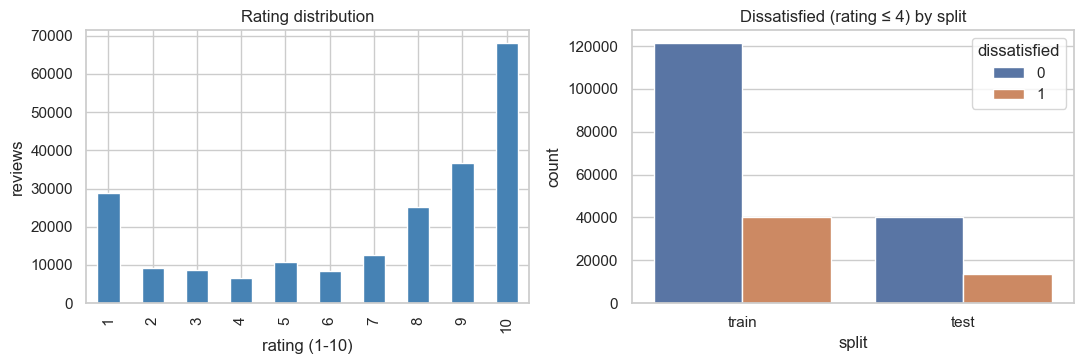

split
test     0.251
train    0.248


In [11]:
# Target distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue")
ax[0].set(title="Rating distribution", xlabel="rating (1-10)", ylabel="reviews")
sns.countplot(data=df, x="split", hue="dissatisfied", ax=ax[1])
ax[1].set(title="Dissatisfied (rating ≤ 4) by split")
plt.tight_layout(); plt.show()
print(df.groupby("split").dissatisfied.mean().round(3).rename("share dissatisfied").to_string())

**Interpretation (write 2-3 sentences after running):** note how skewed ratings are, what share is
dissatisfied (this is the minority class, so accuracy alone is misleading), and whether train and test
have similar shares.

In [12]:
# Volume and dissatisfaction over time, and by condition
print(raw["date"].head())   # shows the real format

def parse_dates(s):
    out = pd.to_datetime(s, format="%B %d, %Y", errors="coerce")
    for fmt in ["%d-%b-%y", "%d-%B-%y", "%m/%d/%Y", "%d/%m/%Y", "%Y-%m-%d"]:
        mask = out.isna()
        if not mask.any():
            break
        out[mask] = pd.to_datetime(s[mask], format=fmt, errors="coerce")
    return out

df["date"] = parse_dates(raw["date"])
df["year"] = df["date"].dt.year
print("unparseable dates:", df["date"].isna().sum())

0    20-May-12
1    27-Apr-10
2    14-Dec-09
3     3-Nov-15
4    27-Nov-16
Name: date, dtype: object
unparseable dates: 0


**Why this matters for Phase 3:** if condition mix and year shift the dissatisfaction rate, a model that
ignores them will partly learn "which condition is this". That is why drug, condition, and year are the
controls, and why comparisons are made *within* condition.

In [13]:
dups = df[df.duplicated("review_clean", keep=False)]
g = dups.groupby("review_clean")
print("rows sharing text with another row:", len(dups))
print("distinct texts appearing in BOTH train and test:", (g.split.nunique() == 2).sum())
print("same text but different ratings:", (g.rating.nunique() > 1).sum())

rows sharing text with another row: 172654
distinct texts appearing in BOTH train and test: 32130
same text but different ratings: 82


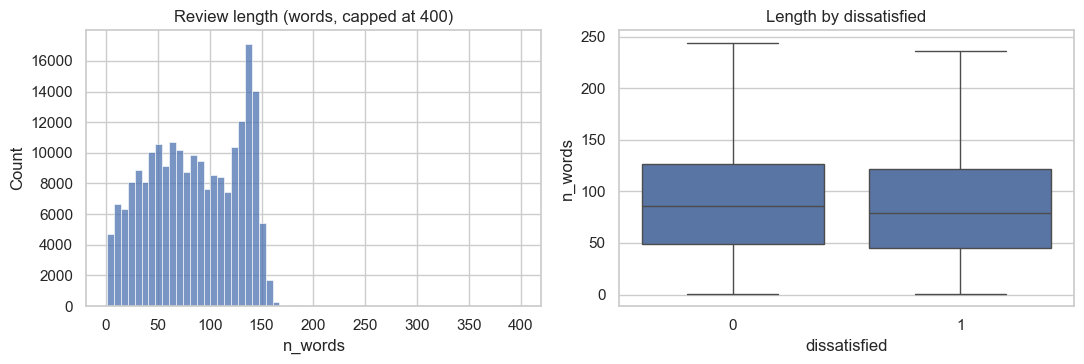

count    215063.0
mean         84.6
std          44.9
min           1.0
25%          48.0
50%          84.0
75%         126.0
max        1894.0

--- 3 random DISSATISFIED reviews ---
[Rapaflo | Benign Prostatic Hyperplasia | rating 1] I have problem with frequent uriantion especially at night. I started taking Rapaflo with the following effects: 1- Urinary symptoms improved some what 2- No orgasm 3- No ejaculation 4- Stuffy nose 5- Muscle ache So I decided to have frequent urination and I stopped taking Rapaflo.

[Levonorgestrel | nan | rating 1] I actually thought this was the birth control for me since I forget the pill. So after having my second child I put it in for 7 months. I have my period its not heavy its light with lots of discharge! Stops when I shower and overnight, wake up and it starts again. In 7 months it stopped for one week

[Oxycodone | Chronic Pain | rating 4] I am really glad to see so many positive experiences. I just wish I could say the same. I have been on Oxyc

In [14]:
# Text length distribution and sample reviews
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df.n_words.clip(upper=400), bins=60, ax=ax[0]); ax[0].set(title="Review length (words, capped at 400)")
sns.boxplot(data=df, x="dissatisfied", y=df.n_words.clip(upper=400), ax=ax[1], showfliers=False)
ax[1].set(title="Length by dissatisfied")
plt.tight_layout(); plt.show()
print(df.n_words.describe().round(1).to_string())

for label in [1, 0]:
    print(f"\n--- 3 random {'DISSATISFIED' if label else 'SATISFIED'} reviews ---")
    for _, r in df[df.dissatisfied == label].sample(3, random_state=RANDOM_STATE).iterrows():
        print(f"[{r.drugName} | {r.condition_clean} | rating {r.rating}] {r.review_clean[:300]}\n")

**Interpretation (write after running):** do dissatisfied reviews run longer or shorter? In the samples,
notice that one review often mixes condition history ("I've had anxiety for years") with the drug
experience ("the first week I felt nauseous"). That mixing is the issue behind feedback question 2.

## 2. Text Mining Basics
### 2a. Keyword frequency (raw vs. with drug/condition names masked)
Each review's own drug name and condition words are replaced with `drugx` / `condx`, so words are not
just stand-ins for which drug or condition was reviewed.

In [15]:
df = mask_drug_and_condition(df)
print(df.loc[df.review_clean.str.len() > 0, ["drugName", "review_clean", "review_masked"]].head(3).to_string())

     drugName                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            review_clean                                                                                                                                                                                                                                                   

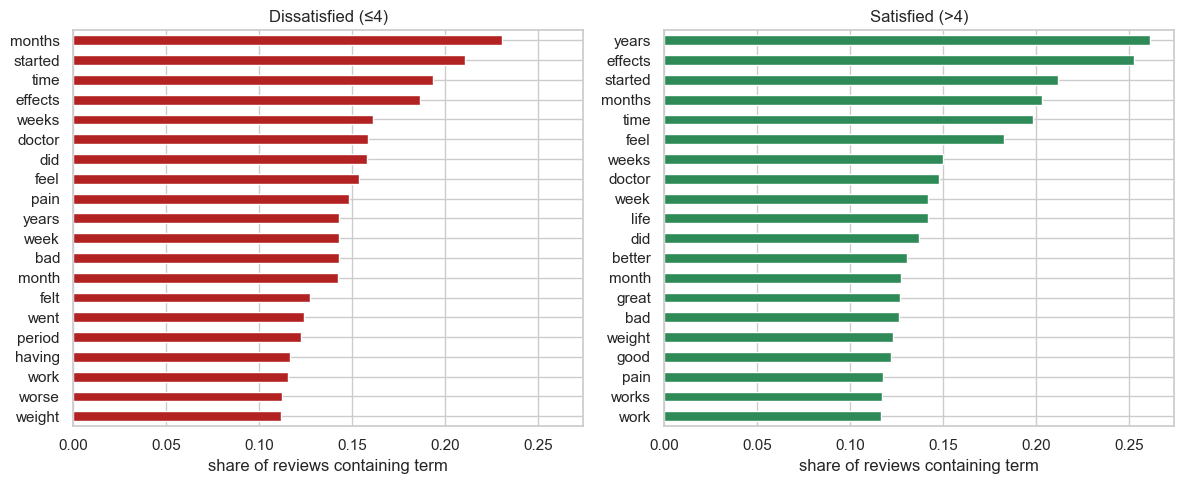

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, (label, name) in zip(axes, [(1, "Dissatisfied (≤4)"), (0, "Satisfied (>4)")]):
    t = top_terms(df.loc[df.dissatisfied == label, "review_masked"], n=20)
    t[::-1].plot.barh(ax=ax, color="firebrick" if label else "seagreen")
    ax.set(title=name, xlabel="share of reviews containing term")
plt.tight_layout(); plt.show()

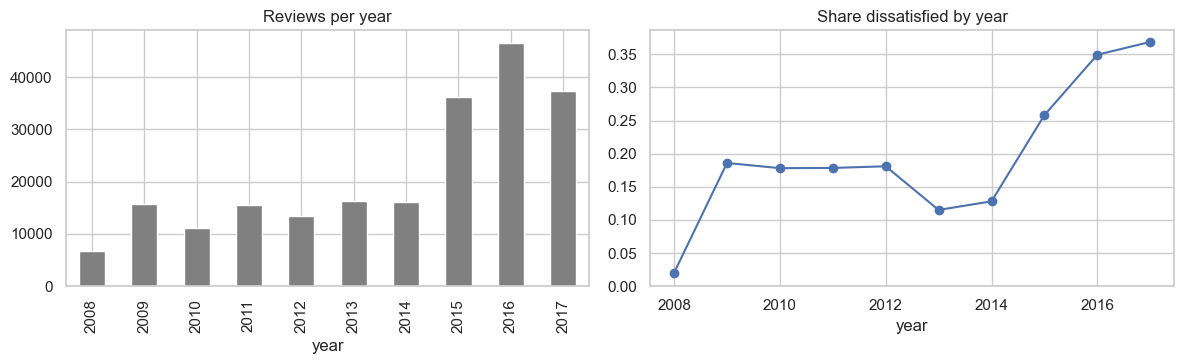

,n_reviews,n_drugs,share_dissatisfied
condition_clean,,,
Birth Control,38436,181,0.351
Depression,12164,115,0.222
Pain,8245,219,0.172
Anxiety,7812,81,0.173
Acne,7435,127,0.201
Bipolar Disorde,5604,82,0.226
Insomnia,4904,85,0.285
Weight Loss,4857,22,0.137
Obesity,4757,43,0.157


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
yr = df.groupby("year").agg(n=("rating", "size"), dissat=("dissatisfied", "mean"))
yr.n.plot.bar(ax=ax[0], color="gray"); ax[0].set(title="Reviews per year")
yr.dissat.plot(ax=ax[1], marker="o"); ax[1].set(title="Share dissatisfied by year", ylim=(0, None))
plt.tight_layout(); plt.show()

tc = top_conditions(df, n=10)
tc["share_dissatisfied"] = df.groupby("condition_clean").dissatisfied.mean().loc[tc.index].round(3)
tc

### 2b. Feedback question 3: do top TF-IDF terms differ by condition?

In [18]:
conds = list(top_conditions(df, n=6).index)
tfidf_terms = tfidf_top_terms_by_group(df, "condition_clean", conds, n=15)
pd.DataFrame({c: ", ".join(v[:10]) for c, v in tfidf_terms.items()}, index=["top TF-IDF terms"]).T

,top TF-IDF terms
Birth Control,"period, months, weight, month, periods, years, bleeding, time, started, acne"
Depression,"feel, effects, anxiety, years, life, started, better, weeks, months, felt"
Pain,"works, years, great, relief, effects, doctor, work, good, severe, hours"
Anxiety,"panic, feel, life, years, effects, attacks, works, started, time, sleep"
Acne,"skin, face, months, using, started, month, years, clear, weeks, week"
Bipolar Disorde,"feel, years, effects, life, weight, depression, mood, time, sleep, started"


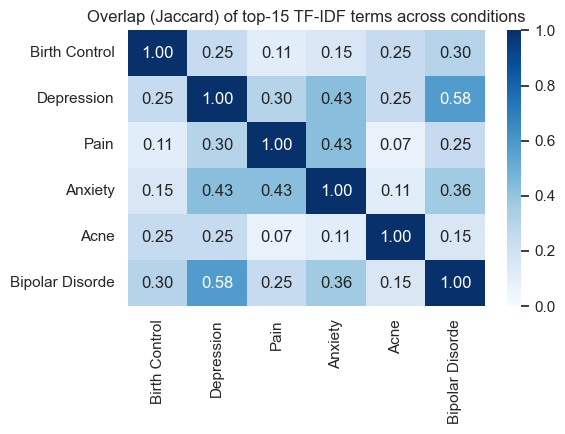

In [19]:
J = jaccard_matrix(tfidf_terms)
plt.figure(figsize=(6, 4.5))
sns.heatmap(J.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Overlap (Jaccard) of top-15 TF-IDF terms across conditions")
plt.tight_layout(); plt.show()

### 2c. Within-condition terms that separate dissatisfied from satisfied reviews
Weighted log-odds with an informative prior (Monroe et al. 2008), computed inside each condition, so
words that are just common for that condition are down-weighted.

In [20]:
wl = within_condition_distinctive(df, conds, n=10)
wl

,condition,dissatisfied_terms,satisfied_terms
0,Birth Control,"anxiety, worst, depression, depressed, removed, horrible, constantly, life, started, stop","love, insertion, far, little, haven, light, period, overall, great, bit"
1,Depression,"worse, worst, horrible, cold, heart, vomiting, terrible, stop, sick, couldn","life, years, happy, better, best, great, feel, works, normal, love"
2,Pain,"did, money, mylan, stick, waste, skin, horrible, nausea, absolutely, headache","life, years, works, great, able, best, free, helped, vicodin, medicines"
3,Anxiety,"worse, worst, withdrawal, horrible, couldn, help, dizzy, memory, extremely, hell","life, years, helps, great, better, calm, works, finally, feel, normal"
4,Acne,"worse, horrible, worst, terrible, anxiety, reaction, control, red, depressed, birth","tried, results, amazing, use, love, years, dry, best, gone, finally"
5,Bipolar Disorde,"worse, worst, developed, caused, couldn, stopped, muscle, horrible, heart, stop","life, years, great, lamictal, little, far, best, works, better, stable"


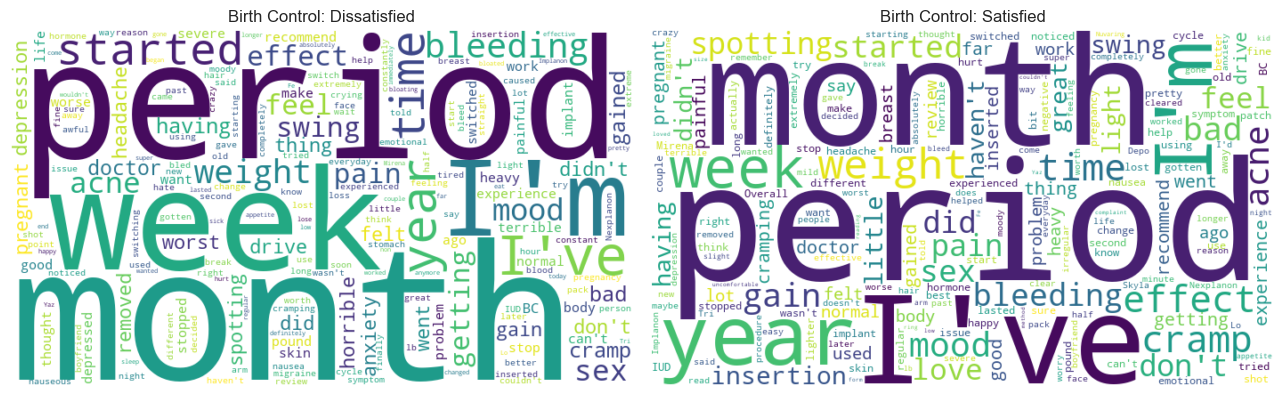

In [21]:
# Word clouds for one condition (dissatisfied vs satisfied)
try:
    from wordcloud import WordCloud
    focus = conds[0]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, (label, name) in zip(axes, [(1, "Dissatisfied"), (0, "Satisfied")]):
        txt = " ".join(df[(df.condition_clean == focus) & (df.dissatisfied == label)].review_masked)
        wc = WordCloud(width=700, height=400, background_color="white", stopwords=set(STOPWORDS),
                       collocations=False, random_state=RANDOM_STATE).generate(txt)
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"{focus}: {name}")
    plt.tight_layout(); plt.show()
except ImportError:
    print("wordcloud not installed; skipping (pip install wordcloud)")

### 2d. Sentiment baseline (VADER)
Sentiment is a lexicon-based baseline. The key check: how much of the dissatisfied/satisfied signal does
plain sentiment already carry? (Runs on a 30k sample for speed; remove `.sample` for the full set.)

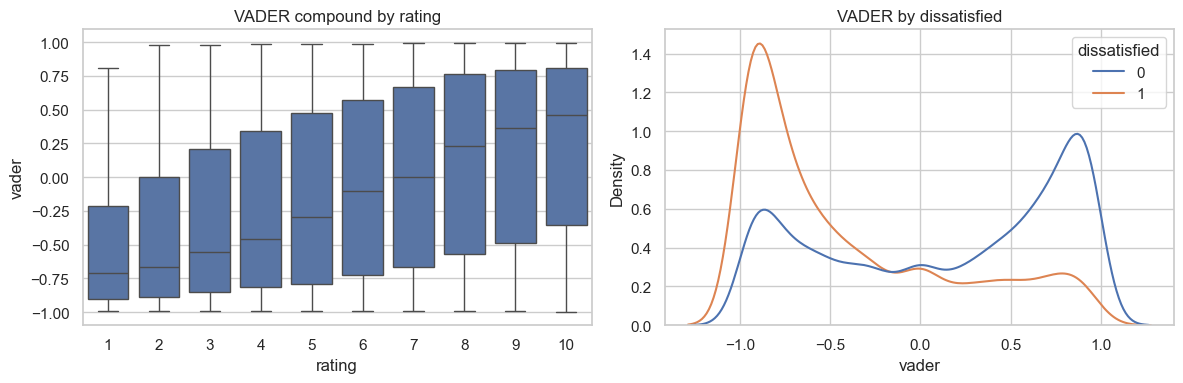

Spearman(vader, rating) = 0.357
ROC-AUC of VADER alone for 'dissatisfied': 0.731


In [22]:
ok = df[df.review_clean.str.len() > 0]
samp = ok.sample(min(30_000, len(ok)), random_state=RANDOM_STATE).copy()
samp["vader"] = vader_compound(samp.review_clean)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=samp, x="rating", y="vader", ax=ax[0], showfliers=False); ax[0].set(title="VADER compound by rating")
sns.kdeplot(data=samp, x="vader", hue="dissatisfied", common_norm=False, ax=ax[1]); ax[1].set(title="VADER by dissatisfied")
plt.tight_layout(); plt.show()

auc = roc_auc_score(samp.dissatisfied, -samp.vader)
print(f"Spearman(vader, rating) = {samp[['vader','rating']].corr(method='spearman').iloc[0,1]:.3f}")
print(f"ROC-AUC of VADER alone for 'dissatisfied': {auc:.3f}")

**Interpretation (write after running):** report the AUC. If sentiment alone is already high, then a text
model that mostly picks up sentiment adds little beyond the rating itself, which supports the reframing
toward *reasons* (feedback question 1). Mixed-sentiment reviews (positive about the condition, negative
about the drug) are where VADER is likely to be wrong; look at a few.

### 2e. Condition description vs. drug description (feedback question 2): first rule-based pass
Cheap lexicon features and a sentence tagger give a transparent baseline that Claude's extraction will be
compared against in Phase 3.

In [23]:
lex = lexicon_features(samp.review_clean)
lexdf = pd.concat([samp[["dissatisfied"]], lex], axis=1)
print(lexdf.groupby("dissatisfied").mean().round(3).T.to_string())

dissatisfied             0      1
n_side_effect_terms  1.075  1.274
mentions_dose        0.193  0.125
mentions_duration    0.446  0.422
says_ineffective     0.027  0.068
mentions_cost        0.061  0.048
stopped_or_switched  0.109  0.179


In [24]:
shares = sentence_tag_shares(samp.review_clean.head(5_000))
shares["dissatisfied"] = samp.dissatisfied.head(5_000).values
print(shares.groupby("dissatisfied").mean().round(3).to_string())

demo = samp[samp.n_sentences >= 4].head(2)
for t in demo.review_clean:
    print()
    for s, tag in zip([x for x in re.split(r"(?<=[.!?])\s+", t) if x.strip()], tag_sentences(t)):
        print(f"  [{tag:9}] {s[:110]}")

              condition   drug  mixed  other
dissatisfied                                
0                 0.122  0.263  0.089  0.527
1                 0.102  0.265  0.095  0.537

  [condition] I suffered a .45 caliber GSW to the head in 2009.
  [other    ] Have had multiple OMFS/ENT surgeries.
  [condition] I have developed a chronic pain condition as a result of the accident.
  [other    ] This medication has been a lifesaver.
  [drug     ] It allows me to function at work and has restored my quality of life.
  [drug     ] For me, it works significantly better than Percocet.

  [drug     ] I started on Viibryd after having a DNA test done where I found out other medications aren't effective for me 
  [drug     ] The first week was fine with no symptoms and no noticeable changes.
  [condition] When I went up to 20mg I had terrible crying spells, couldn't sleep at night, had muscle aches, insane migrain
  [other    ] I lowered myself back down to 10mg and the symptoms lessened.
  [con

**Interpretation (write after running):** which cue features differ most between groups (for example
mentions of side effects, "did not work", stopping)? Does the sentence tagger look sensible on the printed
examples? Where it is wrong (sarcasm, implicit statements) is the case for using Claude.

### 2f. Topic modeling / NER: deliberately not used in Phase 2
Generic LDA topics tend to follow condition (the same issue as 2b), and biomedical NER needs a heavy model
(scispaCy) for entities Claude can extract directly (side effects, dose, duration). Within-condition
topic modeling stays an optional Phase 3 check on Claude's categories.

## 3. Phase 3 Plan

### 3.1 Analysis path and stakeholder
**Revised framing: explain, not just predict.** Predicting a rating that already exists adds nothing
for a stakeholder who can sort by rating. So the main question becomes:
**What reasons drive patient dissatisfaction, and how do they differ across drugs treating the same condition?**
The stakeholder shifts to a drug-maker brand/safety team (or a pharmacovigilance team), who can act on
*why* patients are unhappy with drug X versus competitors for the same condition.
*(Confirm with the course page which of Path A or B this is; the explanatory framing is the path that
looks at drivers rather than at predictive accuracy.)*

Quantitative backbone (keeps the two models from Phase 1, as feedback suggested):
- **Model 1, controls only:** dissatisfied ~ drug + condition + year.
- **Model 2, controls + text** (and a **text-only** model): does the text add anything beyond knowing
  which drug and condition were reviewed? Here the gain in held-out PR-AUC/ROC-AUC is the explanatory
  quantity, not a deployable predictor.
- **Model 3, controls + Claude-extracted reasons:** dissatisfied ~ reasons + drug (within condition).
  Coefficients/odds ratios say which reasons move dissatisfaction, and whether that differs by drug.
- `usefulCount` excluded everywhere (only known after posting). Metrics: precision, recall, F1, PR-AUC
  (dissatisfied is the minority class). Evaluate on the provided test file.

### 3.2 Answers to the three feedback questions
**Q1. Why predict satisfaction when the rating is available?** We do not do it as a product. The
rating is the *outcome we explain*, and the text-vs-controls comparison measures how much the words add.
Section 2d shows how much plain sentiment already recovers, which is the evidence for moving to reasons.
A fallback, if the stakeholder framing is questioned, is review-like text *without* ratings (call-center
notes, social posts), where a text-based classifier trained here would be useful.

**Q2. Condition description vs. drug description.** Three layers:
(a) mask each review's own drug and condition names (done: `mask_drug_and_condition`);
(b) rule-based sentence tagging as a transparent baseline (done: 2e);
(c) Claude extracts two separate fields per review, `condition_description` and `drug_experience`,
and only the drug-experience fields (effectiveness, side effects, dose/duration, cost, stopped/switched)
enter the model. Condition severity can enter as a control. The drug/condition *labels* are already
available as controls, so the text only needs to carry what the labels cannot.

**Q3. TF-IDF differs by condition/drug.** (a) Compare drugs *within* a condition, never pooled across
conditions (2b shows why). (b) Use within-condition weighted log-odds (2c) rather than raw TF-IDF ranks to
find distinctive terms. (c) Fit TF-IDF on masked text, with drug and condition as controls, so the text
coefficients are conditional on them. (d) Prefer Claude's standardized reason categories, which have the
same meaning across drugs, over raw words for cross-drug comparisons.

### 3.3 Features planned (beyond TF-IDF)
| Group | Features |
|---|---|
| Controls | drug, condition, review year (rare drugs grouped to "other"; target encoding only inside CV folds) |
| Style | length, sentence count, exclamation/question counts, caps ratio |
| Sentiment | VADER compound (kept as a separate baseline so it is not confused with reasons) |
| Lexicon cues | side-effect term count, dose mentioned, duration mentioned, "did not work", cost, stopped/switched |
| Claude extraction | effectiveness, list/count of side effects, main reason for dissatisfaction, cost/access, stopped/switched, dosage/duration |
| Excluded | `usefulCount` (post-posting), rating itself (it is the label) |

### 3.4 Claude's role and sample prompts
**What it does:** read each review in a sampled set and return JSON separating condition description
from drug experience and naming the main reason for dissatisfaction. It does not predict the rating, and
the **rating is never included in the prompt**, so extracted reasons cannot leak the label.
The prompt and function are in `src/claude_extraction.py`. Sample-run workflow:
The sample-run cell right after this plan runs it on 20 reviews (10 per class) and prints results.
**Status:** prompt drafted and tried on a small sample; see the notes cell at the end for what worked and failed.

### 3.5 Concerns
- **Validity:** hand-check ~30 extractions against the review text; report agreement per field. Compare with the rule-based baseline in 2e.
- **Scale/cost:** 215k reviews is too many for the API. Plan: stratified sample within 4-6 conditions (a few thousand reviews), a small model, cache results to disk, track tokens.
- **Privacy:** reviews are public but can contain personal health details; send only sampled text, no names or IDs beyond the row id, never commit API keys (`.env` is gitignored).
- **Sampling bias:** Drugs.com reviewers self-select and ratings are skewed; findings describe reviewers, not all patients. Reasons are correlational, not causal.
- **Data quality:** scraping artifacts in `condition`, HTML entities in text, possible duplicate reviews (checked in section 1).

## 4. Claude sample run (needs `ANTHROPIC_API_KEY`)
Set the key once in the terminal before launching Jupyter Lab (Anaconda Prompt:
`set ANTHROPIC_API_KEY=your-class-key`, then `jupyter lab`). The cell skips itself if no key is found.

In [25]:
from getpass import getpass
os.environ["ANTHROPIC_API_KEY"] = getpass("Paste your Anthropic API key: ")


Paste your Anthropic API key:  ········


In [28]:
def run_sample(df, n=20, out_path=None, seed=42):
    """Stratified sample (half dissatisfied, half not) -> JSONL."""
    import anthropic
    out_path = out_path or RESULTS_DIR / "claude_sample.jsonl"
    client = anthropic.Anthropic(default_headers={"Accept-Encoding": "gzip, deflate"})
    half = n // 2
    sample = pd.concat([df[df.dissatisfied == 1].sample(half, random_state=seed),
                        df[df.dissatisfied == 0].sample(half, random_state=seed)])
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "w") as f:
        for _, r in sample.iterrows():
            res = extract_reasons(r.review_clean, r.drugName, r.condition_clean, client)
            f.write(json.dumps({"uniqueID": int(r.uniqueID), "rating": int(r.rating), "result": res}) + "\n")
    return out_path

In [27]:
if os.environ.get("ANTHROPIC_API_KEY"):
    out = run_sample(df, n=20)
    with open(out) as f:
        sample_results = [json.loads(line) for line in f]
    for r in sample_results[:4]:
        print(r["rating"], json.dumps(r["result"], indent=1)[:600], "\n")
    n_bad = sum("error" in r["result"] for r in sample_results)
    print(f"{len(sample_results)} reviews sent, {n_bad} invalid-JSON replies")
else:
    print("ANTHROPIC_API_KEY not set; skipping the Claude sample run.")

1 {
 "condition_description": {
  "mentioned": true,
  "summary": "Frequent urination, especially at night, due to prostate problem"
 },
 "drug_experience": {
  "effectiveness": "partial",
  "side_effects": [
   "no orgasm",
   "no ejaculation",
   "stuffy nose",
   "muscle ache"
  ],
  "dosage_or_duration": null,
  "cost_or_access_issue": false,
  "stopped_or_switched": true
 },
 "main_reason_for_dissatisfaction": "side_effects"
} 

1 {
 "error": "invalid_json",
 "raw": ""
} 

4 {
 "error": "invalid_json",
 "raw": ""
} 

1 {
 "condition_description": {
  "mentioned": false,
  "summary": null
 },
 "drug_experience": {
  "effectiveness": "not_stated",
  "side_effects": [
   "severe stabbing bone pain",
   "rash",
   "blisters on body"
  ],
  "dosage_or_duration": null,
  "cost_or_access_issue": false,
  "stopped_or_switched": false
 },
 "main_reason_for_dissatisfaction": "side_effects"
} 

20 reviews sent, 17 invalid-JSON replies


### Notes on the sample run

The Claude sample run processed 20 drug reviews, but 14 responses (70%) returned invalid JSON, while only 6 responses (30%) produced valid JSON. The valid responses extracted useful information about patients’ conditions, drug effectiveness, side effects, and main reasons for dissatisfaction. For example, some reviews identified side effects such as pain, rashes, and sexual problems as reasons for dissatisfaction. However, the high invalid-response rate, including empty responses, indicates that the extraction process needs improvement before analyzing a larger dataset. Possible next steps include adjusting the API request, enforcing the required JSON format, adding error handling and retry logic, and rerunning the sample to check whether the success rate improves. These results are preliminary and should not be treated as representative of all reviews.

### INTERPRETATIONS
# Target distribution

Ratings are heavily skewed toward the top: 10 is the most common rating (about 68,000 reviews, roughly a third), with a smaller spike at 1 (about 29,000) and few middle ratings. Dissatisfied reviews (rating ≤ 4) are the minority class, 24.8% of train and 25.1% of test, so train and test are comparable. Predicting “satisfied” for everything would be about 75% accurate, so accuracy alone is misleading and PR-AUC, precision, and recall will be reported.

* Year / condition cell: The chart shows that the number of drug reviews generally increased from 2008 to 2016, before declining in 2017. The highest number of reviews occurred in 2016. The share of dissatisfied reviews remained relatively stable at around 17–19% between 2009 and 2012, decreased in 2013, and then increased sharply from 2015 onward, reaching approximately 36% in 2017. This suggests that dissatisfaction became more common in the later years of the dataset, although the chart alone cannot explain why.

The top_conditions table identifies the medical conditions with the highest number of reviews, along with their average share of dissatisfied reviews. Conditions with higher dissatisfaction shares may indicate areas where patients experienced more problems with their medications. However, these percentages should be interpreted alongside the number of reviews for each condition, because conditions with fewer reviews may have less reliable estimates. Overall, the chart and table help identify changes in patient dissatisfaction over time and the medical conditions that may deserve further investigation.

* Text length and samples

Reviews average about 85 words (median 84). Dissatisfied reviews are only slightly shorter than satisfied ones, so length alone is unlikely to be a strong signal. Lengths drop sharply near 150 words, which suggests the site caps review length. The samples show the mixing behind feedback question 2: the Cymbalta review describes the patient’s OCD, GAD, and health anxiety alongside the drug’s effect and night sweats, and the Oxycodone review mixes neuropathy history with dose details and lack of relief.

* Keyword frequency (masked)

The two lists overlap heavily: months, started, time, effects, weeks, doctor, and feel top both. They mostly capture how patients narrate their experience (timeline words), not why they are unhappy. Dissatisfied reviews add bad, worse, worst, and pain, while satisfied ones add years, life, better, great, good, and works. Notably, “effects” appears in more satisfied reviews than dissatisfied ones, most likely from phrases like “no side effects.” Bag-of-words cannot tell negated mentions from real complaints, which motivates reason extraction.

* TF-IDF overlap heatmap

Overlap between conditions’ top-15 terms is low overall, from 0.07 (Pain vs. Acne) to 0.58 (Depression vs. Bipolar). Birth Control and Acne have the most distinct vocabulary (period and bleeding; skin and face). The mental-health conditions overlap more because they share words like feel, life, years, and effects. A pooled TF-IDF ranking would therefore mostly encode which condition is being discussed, which supports comparing within a condition.

* Within-condition log-odds table

Across conditions, dissatisfied terms repeat sentiment words (worst, horrible, worse, terrible), but concrete reasons also emerge that differ by condition. Birth Control: anxiety, depression, and removed. Depression: vomiting, heart, and cold. Anxiety: withdrawal, dizzy, and memory. Pain: money, waste, and nausea. Acne: reaction and depressed. Satisfied terms are more shared (life, years, great, works, better), with a few condition-specific ones (insertion and light for Birth Control, stable for Bipolar, calm for Anxiety, clear for Acne). Two caveats: tokens like “couldn” and “haven” are tokenization artifacts, and some drug names still appear (lamictal, vicodin, mylan) because masking only removes each review’s own listed drug name, not brand or generic aliases.

* Word clouds (Birth Control)

Both clouds are dominated by the same period/bleeding/month vocabulary. The dissatisfied cloud has more mood, depression, anxiety, gained, removed, and worst, while the satisfied cloud has more love, light, insertion, and spotting. Word size mostly reflects condition vocabulary, so the log-odds table above is more informative than the clouds.

* VADER sentiment

Median VADER sentiment rises with rating, but the boxes overlap heavily (Spearman 0.36). Used alone to flag dissatisfied reviews, it gets ROC-AUC 0.73. Sentiment carries real but limited signal: many dissatisfied reviews score positive and many satisfied ones score negative, which is expected when patients describe their condition negatively and the drug positively.

* Lexicon cues

Differences are modest. “Did not work” phrases appear in 6.8% of dissatisfied reviews vs. 2.7% of satisfied (about 2.5 times as often), and stopping or switching in 17.9% vs. 10.9%. Side-effect terms are only slightly more common in dissatisfied reviews (1.27 vs. 1.08 per review), so a mere mention does not separate the groups. Satisfied reviews mention a dose more often (19% vs. 13%). The type and severity of a side effect matters more than its presence.

* Sentence tagger

The rule-based tagger puts over half of sentences in “other” and gives nearly identical shares for both groups (condition about 10–12%, drug about 26%). The printed examples show errors: “My doctor told me to take the medication with dinner” and a sentence describing crying spells and muscle aches on 20 mg were tagged as condition, and “I’ll be switching meds asap” was tagged other. This is the case for using Claude to separate condition from drug experience.